# Global Prochlorococcus Gene Prevalence Estimates

The purpose of this notebook is to generate a global estimate of the prevalence of every
known gene family in the Prochlorococcus pangenome.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from gene_prevalence import BernoulliPrevalenceModel
from matplotlib.patches import Wedge, Patch

# instatiate random number generator with fixed seed for reproducibility
rng = np.random.default_rng(seed=9481)

# significance level for confidence intervals
ci_alpha = 0.05

In [2]:
# set aesthetic parameters

line_color = '#0F0A0A'    # dark

neutral_color = '#E0E0E0'

# thursday
accent_colors = ['#9B5DE5', '#FFAC69', '#00C9AE', '#FD3F92', '#0F0A0A', 
                 '#959AB1', '#FFDB66', '#63B9FF','#FFB1CA', '#4F1DD7']

style = {'axes.edgecolor': line_color,
         'axes.labelcolor': line_color,
         'text.color': line_color,
         'xtick.color': line_color,
         'ytick.color': line_color,
         'font.family': 'Helvetica',
         'font.Helvetica': ['Helvetica']}

palette = sns.color_palette(accent_colors)

sns.set_context('talk', rc={'lines.linewidth': 2})
sns.set_palette(palette)
sns.set_style('ticks', style)

plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.bottom'] = True
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['patch.linewidth'] = 0
plt.rcParams['patch.edgecolor'] = 'none'
plt.rcParams['savefig.dpi'] = 300

In [3]:
# import pro relative abundances by biome and clade (from GRUMP, processed by Yubin)

# directory paths
project_root = Path.cwd().resolve().parent
data_dir = project_root / "data" / "inputs"

# pro relative abundances by biome and clade
pro_rel_abund_df = pd.read_csv(data_dir / "Pro_Ecotype_Recipe_Rel_Abundance.csv")
pro_rel_abund_df['biome'] = pro_rel_abund_df['manual.bin'].str.split('_').str[0]
pro_rel_abund_df['depth_bin'] = pro_rel_abund_df['manual.bin'].str.split('_').str[1].map(
    {'upper50m': '0-50m', '50to100m': '50-100m', '100to200m': '100-200m'})

# rename columns for consistency
pro_rel_abund_df = pro_rel_abund_df.rename(columns={
    'manual.bin': 'bin', 
    'ProSynTax': 'clade', 
    'RelAbundance': 'rel_abundance'
    })

# drop the column just used for plotting
pro_rel_abund_df = pro_rel_abund_df.drop(columns=['ProSynTax_plot'])

pro_rel_abund_df

,bin,clade,rel_abundance,biome,depth_bin
0,Coastal_50to100m,AMZ-I,0.013898,Coastal,50-100m
1,Coastal_50to100m,HLI,0.068952,Coastal,50-100m
2,Coastal_50to100m,HLII,0.450615,Coastal,50-100m
3,Coastal_50to100m,HLVI,0.006128,Coastal,50-100m
4,Coastal_50to100m,LLI,0.152467,Coastal,50-100m
...,...,...,...,...,...
82,Westerlies_upper50m,HLIII,0.036329,Westerlies,0-50m
83,Westerlies_upper50m,HLIV,0.007898,Westerlies,0-50m
84,Westerlies_upper50m,HLVI,0.014557,Westerlies,0-50m
85,Westerlies_upper50m,LLI,0.057462,Westerlies,0-50m


In [4]:
# import pro cell counts global climatology 
# (from [Visintini, Martiny, and Flombaum, 2021](https://doi.org/10.1002/lol2.10188))

# pro cell counts global climatology
pro_cell_counts_df = pd.read_csv(data_dir / "PRO_annual_climatological_mean.csv").rename(
    columns={"Latitude'": 'lat', "Longitude'": 'lon'}
)

pro_cell_counts_df[pro_cell_counts_df["0m'"].notna()]

,lat,lon,0m',5m',10m',15m',20m',25m',30m',35m',...,75m',80m',85m',90m',95m',100m',125m',150m',175m',200m'
27,-43.5,0.5,1000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,...,1000.0,1000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28,-42.5,0.5,3000.0,3000.0,4000.0,4000.0,4000.0,5000.0,5000.0,5000.0,...,2000.0,2000.0,1000.0,1000.0,1000.0,NaN,NaN,NaN,NaN,NaN
29,-41.5,0.5,5000.0,5000.0,5000.0,6000.0,6000.0,6000.0,6000.0,5000.0,...,2000.0,2000.0,2000.0,1000.0,1000.0,1000.0,NaN,NaN,NaN,NaN
30,-40.5,0.5,6000.0,6000.0,7000.0,7000.0,8000.0,8000.0,8000.0,8000.0,...,3000.0,3000.0,3000.0,2000.0,2000.0,2000.0,NaN,NaN,NaN,NaN
31,-39.5,0.5,8000.0,9000.0,10000.0,11000.0,11000.0,12000.0,12000.0,12000.0,...,5000.0,5000.0,4000.0,3000.0,3000.0,2000.0,1000.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41061,63.5,-0.5,3000.0,4000.0,4000.0,4000.0,4000.0,3000.0,2000.0,2000.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
41062,64.5,-0.5,2000.0,3000.0,3000.0,3000.0,3000.0,2000.0,2000.0,1000.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
41063,65.5,-0.5,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,1000.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
41064,66.5,-0.5,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,1000.0,1000.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# import lonhurst province data
# (Version 4 - March 2010, downloaded from https://www.marineregions.org)

# lonhurst provinces shapefile
longhurst = gpd.read_file(data_dir / "longhurst_v4_2010/Longhurst_world_v4_2010.shp").to_crs("EPSG:4326")

longhurst

,ProvCode,ProvDescr,geometry
0,BPLR,Polar - Boreal Polar Province (POLR),"MULTIPOLYGON (((-161.18426 63.5, -161.5 63.5, ..."
1,ARCT,Polar - Atlantic Arctic Province,"MULTIPOLYGON (((-21.51305 64.64409, -21.55945 ..."
2,SARC,Polar - Atlantic Subarctic Province,"MULTIPOLYGON (((11.26472 63.96082, 11.09548 63..."
3,NADR,Westerlies - N. Atlantic Drift Province (WWDR),"POLYGON ((-11.5 57.5, -11.5 56.5, -11.5 55.5, ..."
4,GFST,Westerlies - Gulf Stream Province,"POLYGON ((-43.5 43.5, -43.5 42.5, -43.5 41.5, ..."
5,NASW,Westerlies - N. Atlantic Subtropical Gyral Pro...,"POLYGON ((-39.5 25.5, -40.5 25.5, -41.5 25.5, ..."
6,NATR,Trades - N. Atlantic Tropical Gyral Province (...,"MULTIPOLYGON (((-72.34673 18.53597, -72.36877 ..."
7,WTRA,Trades - Western Tropical Atlantic Province,"POLYGON ((-19.5 -6.5, -20.5 -6.5, -21.5 -6.5, ..."
8,ETRA,Trades - Eastern Tropical Atlantic Province,"POLYGON ((9.5 -12.5, 8.5 -12.5, 7.5 -12.5, 6.5..."
9,SATL,Trades - South Atlantic Gyral Province (SATG),"POLYGON ((-19.5 -6.5, -18.5 -6.5, -17.5 -6.5, ..."


In [6]:
# calculate multiplication factors for each depth range
# these factors indicate the annual mean relative abundance of pro cells in each of
# our biome-depth bins

# aggregate cell counts into three depth ranges: 0-50m, 50-100m, and 100-200m
pro_cell_counts_df['0-50m'] = pro_cell_counts_df.loc[:, "0m'":"50m'"].mean(axis=1)
pro_cell_counts_df['50-100m'] = pro_cell_counts_df.loc[:, "50m'":"100m'"].mean(axis=1)
# multiply by two to account for twice the volume in this depth range
pro_cell_counts_df['100-200m'] = pro_cell_counts_df.loc[:, "100m'":"200m'"].mean(axis=1) * 2

# downsample to only include rows with non-null values in at least one of the depth ranges
pro_agg_df = pro_cell_counts_df[pro_cell_counts_df[['0-50m', '50-100m', '100-200m']].notnull().any(
    axis=1)][['lat', 'lon', '0-50m', '50-100m', '100-200m']].reset_index(drop=True)

# join longhurst provinces with pro cell counts
gridded_pro_df = gpd.GeoDataFrame(
    pro_agg_df,
    geometry=gpd.points_from_xy(pro_agg_df['lon'], pro_agg_df['lat']),
    crs="EPSG:4326"
)

# attach province information to each point
gridded_pro_df = gpd.sjoin(
    gridded_pro_df, longhurst, how='left', predicate='intersects')

# identify biome for each point based on province information
gridded_pro_df['biome'] = gridded_pro_df['ProvDescr'].str.split(' - ').str[0]

# aggregate by biome to get multiplication factor for each biome
pro_factors_df = gridded_pro_df.groupby('biome')[['0-50m', '50-100m', '100-200m']].sum()

# drop polar biome
pro_factors_df = pro_factors_df.loc[pro_factors_df.index != 'Polar']

# drop 100-200m depth range for coastal biome
pro_factors_df.loc['Coastal', '100-200m'] = np.nan

# normalize by the minimum value across all biomes and depth ranges to get multiplication factors
pro_factors_df = pro_factors_df / pro_factors_df.min().min()

pro_factors_df

,0-50m,50-100m,100-200m
biome,,,
Coastal,1.427880,1.000000,NaN
Trades,8.552765,7.526574,5.894504
Westerlies,3.698279,3.473884,3.895178


In [7]:
# calculate global relative abundances by multiplying each clade's relative abundance
# in each biome-depth bin by the corresponding multiplication factor

# add on multiplication factors to pro relative abundances dataframe
global_rel_abund_df = pro_rel_abund_df.merge(
    pro_factors_df.reset_index().melt(var_name='depth_bin', id_vars='biome', value_name='factor'), 
    on=['biome', 'depth_bin'], 
    how='left'
)

# multiply relative abundances by multiplication factors to get global relative abundances
global_rel_abund_df['multiplied_rel_abundance'] = global_rel_abund_df['rel_abundance'] * global_rel_abund_df['factor']

# aggregate by clade to get global relative abundance for each clade
pro_global_rel_abund_df = global_rel_abund_df.groupby('clade')['multiplied_rel_abundance'].sum()
pro_global_rel_abund_df = pro_global_rel_abund_df / pro_global_rel_abund_df.sum()
pro_global_rel_abund_df = pro_global_rel_abund_df.reset_index().rename(
    columns={'multiplied_rel_abundance': 'global_rel_abundance'})

pro_global_rel_abund_df = pro_global_rel_abund_df.sort_values('global_rel_abundance', ascending=False).reset_index(drop=True)

pro_global_rel_abund_df

,clade,global_rel_abundance
0,HLII,0.449453
1,HLI,0.265722
2,LLI,0.178181
3,LLVII,0.047896
4,HLVI,0.013686
5,HLIII,0.012625
6,LLII-LLIII,0.011433
7,LLIV,0.011158
8,AMZ-I,0.005629
9,HLIV,0.003479


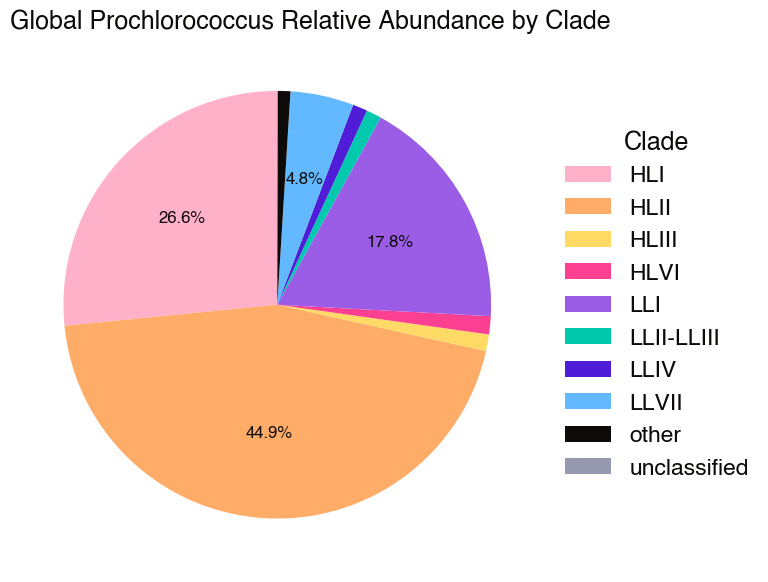

In [8]:
# make pie chart of global relative abundances by clade

# simplify some categories for better visualization
plot_df = pro_global_rel_abund_df.copy()
plot_df.loc[plot_df['clade'].isin(['AMZ-I', 'HLIV', 'LLVIII', 'HLII-HLVI', 'AMZ-III']), 'clade'] = 'other'
plot_df = plot_df.groupby('clade')['global_rel_abundance'].sum().reset_index()

# map clades to colors
clade_color_mapping = {
    'HLI': accent_colors[8],
    'HLII': accent_colors[1],
    'LLI': accent_colors[0],
    'unclassified': accent_colors[5],
    'HLIII': accent_colors[6],
    'LLVII': accent_colors[7],
    'LLII-LLIII': accent_colors[2],
    'LLIV': accent_colors[9],
    'HLVI': accent_colors[3],
    'other': accent_colors[4]
}

# build figure with legends, and only label percentage for clades with >3% global relative abundance
plt.figure(figsize=(8, 8))
plt.pie(
    plot_df['global_rel_abundance'],
    autopct=lambda p: '{:.1f}%'.format(p) if p > 3 else '',
    startangle=90,
    colors=[clade_color_mapping[clade] for clade in plot_df['clade']],
    textprops={'fontsize': 12}
)

plt.legend(title='Clade', loc='center left', bbox_to_anchor=(1, 0.5), labels=plot_df['clade'])
# move title right to center combined pie chart ane legend area
plt.title('Global Prochlorococcus Relative Abundance by Clade', loc='left')
plt.tight_layout()
plt.show()

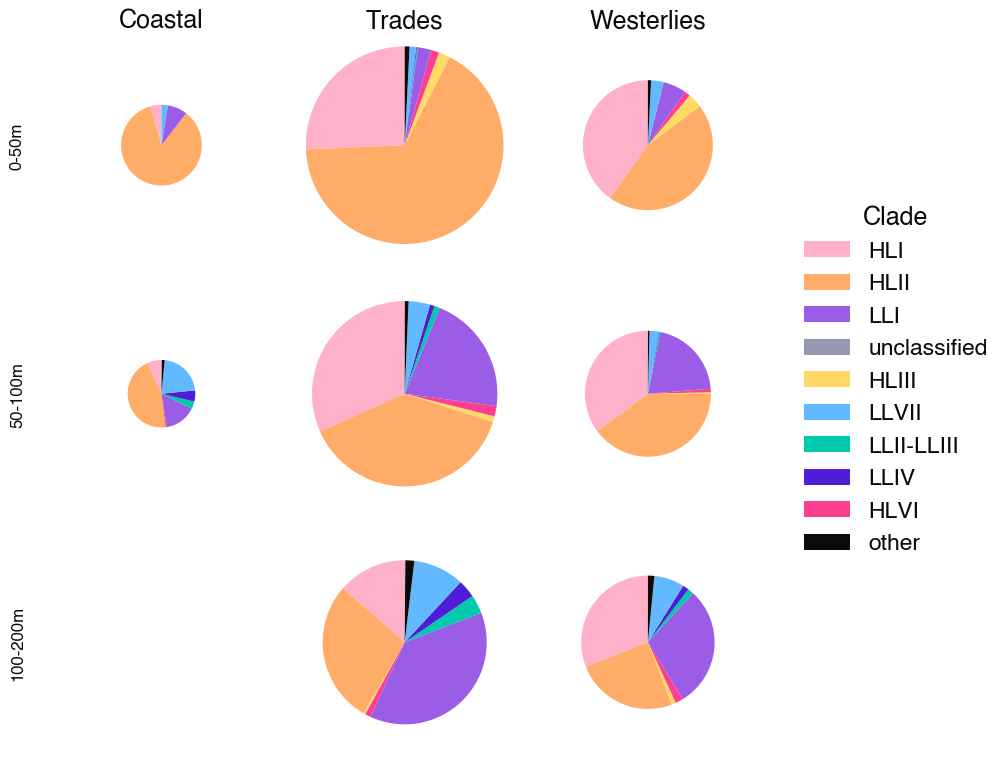

In [9]:
# scaled pie chart of global relative abundances by biome-depth bin

def scaled_pie(ax, values, area_scale=1, colors=None):
    values = np.asarray(values, dtype=float)
    fracs = values / values.sum()

    radius = np.sqrt(area_scale)
    start = 90

    if colors is None:
        colors = plt.cm.tab20(np.linspace(0, 1, len(values)))

    for frac, color in zip(fracs, colors):
        theta = frac * 360
        wedge = Wedge(
            center=(0, 0),
            r=radius,
            theta1=start,
            theta2=start + theta,
            facecolor=color,
            edgecolor="white"
        )
        ax.add_patch(wedge)
        start += theta

    ax.set_aspect("equal")
    ax.set_xlim(-1.1 * max_radius, 1.1 * max_radius)
    ax.set_ylim(-1.1 * max_radius, 1.1 * max_radius)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

# find maximum radius for scaling pies
max_radius = np.sqrt(pro_factors_df.max().max())

# make figure
fig, axes = plt.subplots(3, 3, figsize=(8, 8))

# plot each bin as a separate scaled pie
for i, biome in enumerate(['Coastal', 'Trades', 'Westerlies']):
    for j, depth_bin in enumerate(['0-50m', '50-100m', '100-200m']):
        # filter the data for the current biome and depth bin
        plot_df = pro_rel_abund_df[
            (pro_rel_abund_df['biome'] == biome) &
            (pro_rel_abund_df['depth_bin'] == depth_bin)
        ]
        plot_df.loc[plot_df['clade'].isin(
            ['AMZ-I', 'HLIV', 'LLVIII', 'HLII-HLVI', 'AMZ-III']), 'clade'] = 'other'
        plot_df = plot_df.groupby('clade')['rel_abundance'].sum().reset_index()
        # add color mapping
        plot_df['color'] = plot_df['clade'].map(clade_color_mapping)
        # sort by clade name
        plot_df = plot_df.sort_values('clade')
        # pull out multiplication factor
        factor = pro_factors_df.loc[biome, depth_bin]

        # plot pie
        scaled_pie(axes[j][i], plot_df['rel_abundance'], area_scale=factor, colors=plot_df['color'])

        # label rows and columns
        if i == 0:
            axes[j][i].set_ylabel(
                depth_bin, 
                fontsize=12,
                rotation=90,
                labelpad=20
                )
        if j == 0:
            axes[j][i].set_title(biome)

# figure-level legend
legend_handles = [
    Patch(facecolor=color, label=label)
    for label, color in zip(clade_color_mapping.keys(), clade_color_mapping.values())
]
fig.legend(
    handles=legend_handles,
    title="Clade",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
)

plt.tight_layout()
plt.show()